In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
day4_path = "../data/analysis_data/APL_Day4_Delivery_Performance.csv"

df_day4 = pd.read_csv(
    day4_path,
    encoding="cp1252",
    low_memory=False
)

print("Day 4 dataset loaded successfully.")
print("Shape:", df_day4.shape)

Day 4 dataset loaded successfully.
Shape: (180519, 55)


## Day 5 working copy

In [3]:
df_day5 = df_day4.copy()

print("Day 5 working copy created.")
print("Shape:", df_day5.shape)    

Day 5 working copy created.
Shape: (180519, 55)


## Initial Delay Risk Check

In [4]:
risk_columns = [
    "Late_delivery_risk",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Delay_Severity",
    "Delivery_Status",
    "Shipping Mode",
    "Market",
    "Order Region",
    "Region_Market"
]

display(df_day5[risk_columns].head(10))

,Late_delivery_risk,Is_Delayed,Shipping_Delay_Days,Delay_Severity,Delivery_Status,Shipping Mode,Market,Order Region,Region_Market
0,1,1,2,Major Delay,Delayed,Standard Class,Pacific Asia,South Asia,Pacific Asia - South Asia
1,0,0,0,On Time / Early,On Time,Standard Class,LATAM,Central America,LATAM - Central America
2,0,0,0,On Time / Early,On Time,Standard Class,LATAM,Central America,LATAM - Central America
3,1,1,2,Major Delay,Delayed,Standard Class,USCA,East of USA,USCA - East of USA
4,1,1,2,Major Delay,Delayed,Standard Class,USCA,East of USA,USCA - East of USA
5,1,1,2,Major Delay,Delayed,Standard Class,USCA,East of USA,USCA - East of USA
6,0,0,0,On Time / Early,On Time,Standard Class,LATAM,Central America,LATAM - Central America
7,0,0,0,On Time / Early,On Time,Standard Class,LATAM,Central America,LATAM - Central America
8,0,0,0,On Time / Early,On Time,Standard Class,Europe,Southern Europe,Europe - Southern Europe
9,0,0,0,On Time / Early,On Time,Standard Class,LATAM,Central America,LATAM - Central America


In [5]:
df_day5[risk_columns].info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   Late_delivery_risk   180519 non-null  int64
 1   Is_Delayed           180519 non-null  int64
 2   Shipping_Delay_Days  180519 non-null  int64
 3   Delay_Severity       180519 non-null  str  
 4   Delivery_Status      180519 non-null  str  
 5   Shipping Mode        180519 non-null  str  
 6   Market               180519 non-null  str  
 7   Order Region         180519 non-null  str  
 8   Region_Market        180519 non-null  str  
dtypes: int64(3), str(6)
memory usage: 25.1 MB


## Overall Late Delivery Risk

In [6]:
risk_distribution = (
    df_day5["Late_delivery_risk"]
    .value_counts()
    .sort_index()
)

display(risk_distribution)

Late_delivery_risk
0    81542
1    98977
Name: count, dtype: int64

In [7]:
risk_percentage = (
    df_day5["Late_delivery_risk"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(risk_percentage)

Late_delivery_risk
0    45.17
1    54.83
Name: proportion, dtype: float64

In [8]:
total_shipments = len(df_day5)

high_risk_shipments = (
    df_day5["Late_delivery_risk"] == 1
).sum()

low_risk_shipments = (
    df_day5["Late_delivery_risk"] == 0
).sum()

risk_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipments",
        "High-Risk Shipments",
        "Low-Risk Shipments",
        "High-Risk Rate (%)",
        "Low-Risk Rate (%)"
    ],
    "Value": [
        total_shipments,
        high_risk_shipments,
        low_risk_shipments,
        round(high_risk_shipments / total_shipments * 100, 2),
        round(low_risk_shipments / total_shipments * 100, 2)
    ]
})

display(risk_kpis)

,Metric,Value
0,Total Shipments,180519.00
1,High-Risk Shipments,98977.00
2,Low-Risk Shipments,81542.00
3,High-Risk Rate (%),54.83
4,Low-Risk Rate (%),45.17


## Risk vs Actual Delay

In [9]:
risk_vs_delay = pd.crosstab(
    df_day5["Late_delivery_risk"],
    df_day5["Is_Delayed"],
    margins=True
)

display(risk_vs_delay)

Is_Delayed,0,1,All
Late_delivery_risk,,,
0,77119,4423,81542
1,0,98977,98977
All,77119,103400,180519


In [10]:
risk_vs_delay_pct = pd.crosstab(
    df_day5["Late_delivery_risk"],
    df_day5["Is_Delayed"],
    normalize="index"
).mul(100).round(2)

display(risk_vs_delay_pct)

Is_Delayed,0,1
Late_delivery_risk,,
0,94.58,5.42
1,0.00,100.00


## Create Risk Classification

In [11]:
df_day5["Risk_Status"] = np.where(
    df_day5["Late_delivery_risk"] == 1,
    "High Risk",
    "Low Risk"
)

display(
    df_day5["Risk_Status"].value_counts()
)

Risk_Status
High Risk    98977
Low Risk     81542
Name: count, dtype: int64

In [12]:
print(df_day5["Risk_Status"].unique())

<ArrowStringArray>
['High Risk', 'Low Risk']
Length: 2, dtype: str


## Risk by Shipping Mode

In [13]:
shipping_mode_risk = (
    df_day5
    .groupby("Shipping Mode")
    .agg(
        Total_Shipments=("Late_delivery_risk", "size"),
        High_Risk_Shipments=("Late_delivery_risk", "sum"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum")
    )
)

shipping_mode_risk["Risk_Rate_%"] = (
    shipping_mode_risk["High_Risk_Shipments"]
    / shipping_mode_risk["Total_Shipments"]
    * 100
).round(2)

shipping_mode_risk["Actual_Delay_Rate_%"] = (
    shipping_mode_risk["Actual_Delayed_Shipments"]
    / shipping_mode_risk["Total_Shipments"]
    * 100
).round(2)

shipping_mode_risk = shipping_mode_risk.sort_values(
    "Risk_Rate_%",
    ascending=False
)

display(shipping_mode_risk)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Shipping Mode,,,,,
First Class,27814,26513,27814,95.32,100.00
Second Class,35216,26987,28078,76.63,79.73
Same Day,9737,4454,4657,45.74,47.83
Standard Class,107752,41023,42851,38.07,39.77


## Risk by Market

In [14]:
market_risk = (
    df_day5
    .groupby("Market")
    .agg(
        Total_Shipments=("Late_delivery_risk", "size"),
        High_Risk_Shipments=("Late_delivery_risk", "sum"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum")
    )
)

market_risk["Risk_Rate_%"] = (
    market_risk["High_Risk_Shipments"]
    / market_risk["Total_Shipments"]
    * 100
).round(2)

market_risk["Actual_Delay_Rate_%"] = (
    market_risk["Actual_Delayed_Shipments"]
    / market_risk["Total_Shipments"]
    * 100
).round(2)

market_risk = market_risk.sort_values(
    "Risk_Rate_%",
    ascending=False
)

display(market_risk)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Market,,,,,
Europe,50252,27743,28989,55.21,57.69
Pacific Asia,41260,22712,23649,55.05,57.32
USCA,25799,14138,14744,54.80,57.15
Africa,11614,6340,6598,54.59,56.81
LATAM,51594,28044,29420,54.36,57.02


## Risk by Order Region

In [15]:
region_risk = (
    df_day5
    .groupby("Order Region")
    .agg(
        Total_Shipments=("Late_delivery_risk", "size"),
        High_Risk_Shipments=("Late_delivery_risk", "sum"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum")
    )
)

region_risk["Risk_Rate_%"] = (
    region_risk["High_Risk_Shipments"]
    / region_risk["Total_Shipments"]
    * 100
).round(2)

region_risk["Actual_Delay_Rate_%"] = (
    region_risk["Actual_Delayed_Shipments"]
    / region_risk["Total_Shipments"]
    * 100
).round(2)

region_risk = region_risk.sort_values(
    "Risk_Rate_%",
    ascending=False
)

display(region_risk)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Order Region,,,,,
Central Africa,1677,972,1018,57.96,60.70
South Asia,7731,4350,4523,56.27,58.50
East Africa,1852,1036,1064,55.94,57.45
Western Europe,27109,15140,15863,55.85,58.52
South of USA,4045,2256,2350,55.77,58.10
Eastern Europe,3920,2182,2252,55.66,57.45
East of USA,6915,3849,4009,55.66,57.98
Southeast Asia,9539,5297,5531,55.53,57.98
Central Asia,553,306,316,55.33,57.14


## Risk by Region + Market

In [16]:
region_market_risk = (
    df_day5
    .groupby("Region_Market")
    .agg(
        Total_Shipments=("Late_delivery_risk", "size"),
        High_Risk_Shipments=("Late_delivery_risk", "sum"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum")
    )
)

region_market_risk["Risk_Rate_%"] = (
    region_market_risk["High_Risk_Shipments"]
    / region_market_risk["Total_Shipments"]
    * 100
).round(2)

region_market_risk["Actual_Delay_Rate_%"] = (
    region_market_risk["Actual_Delayed_Shipments"]
    / region_market_risk["Total_Shipments"]
    * 100
).round(2)

region_market_risk = region_market_risk.sort_values(
    "Risk_Rate_%",
    ascending=False
)

display(region_market_risk.head(15))

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Region_Market,,,,,
Africa - Central Africa,1677,972,1018,57.96,60.70
Pacific Asia - South Asia,7731,4350,4523,56.27,58.50
Africa - East Africa,1852,1036,1064,55.94,57.45
Europe - Western Europe,27109,15140,15863,55.85,58.52
USCA - South of USA,4045,2256,2350,55.77,58.10
USCA - East of USA,6915,3849,4009,55.66,57.98
Europe - Eastern Europe,3920,2182,2252,55.66,57.45
Pacific Asia - Southeast Asia,9539,5297,5531,55.53,57.98
Pacific Asia - Central Asia,553,306,316,55.33,57.14


## Delivery Severity Risk

In [17]:
severity_risk = (
    df_day5
    .groupby("Delay_Severity")
    .agg(
        Total_Shipments=("Late_delivery_risk", "size"),
        High_Risk_Shipments=("Late_delivery_risk", "sum"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum")
    )
)

severity_risk["Risk_Rate_%"] = (
    severity_risk["High_Risk_Shipments"]
    / severity_risk["Total_Shipments"]
    * 100
).round(2)

severity_risk["Actual_Delay_Rate_%"] = (
    severity_risk["Actual_Delayed_Shipments"]
    / severity_risk["Total_Shipments"]
    * 100
).round(2)

display(severity_risk)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Delay_Severity,,,,,
Major Delay,42753,41020,42753,95.95,100.0
Minor Delay,60647,57957,60647,95.56,100.0
On Time / Early,77119,0,0,0.00,0.0


## Risk vs Shipping Delay Days

In [18]:
delay_risk_summary = (
    df_day5
    .groupby("Late_delivery_risk")["Shipping_Delay_Days"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .round(2)
)

display(delay_risk_summary)

,count,mean,median,min,max
Late_delivery_risk,,,,,
0,81542,-0.71,-1.0,-2,4
1,98977,1.62,1.0,1,4


## Visualize Risk Distribution

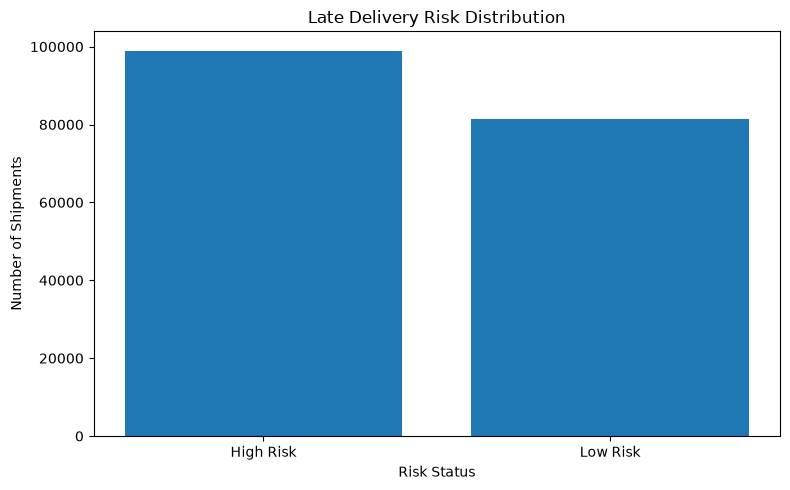

In [19]:
risk_counts = df_day5["Risk_Status"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.title("Late Delivery Risk Distribution")
plt.xlabel("Risk Status")
plt.ylabel("Number of Shipments")

plt.tight_layout()
plt.show()

## Risk Rate by Shipping Mode

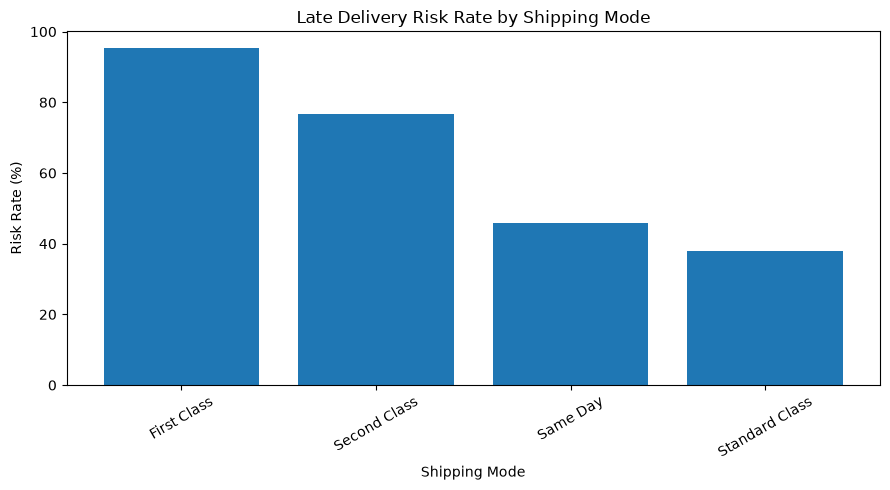

In [20]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_mode_risk.index,
    shipping_mode_risk["Risk_Rate_%"]
)

plt.title("Late Delivery Risk Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Risk Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Risk Rate by Market

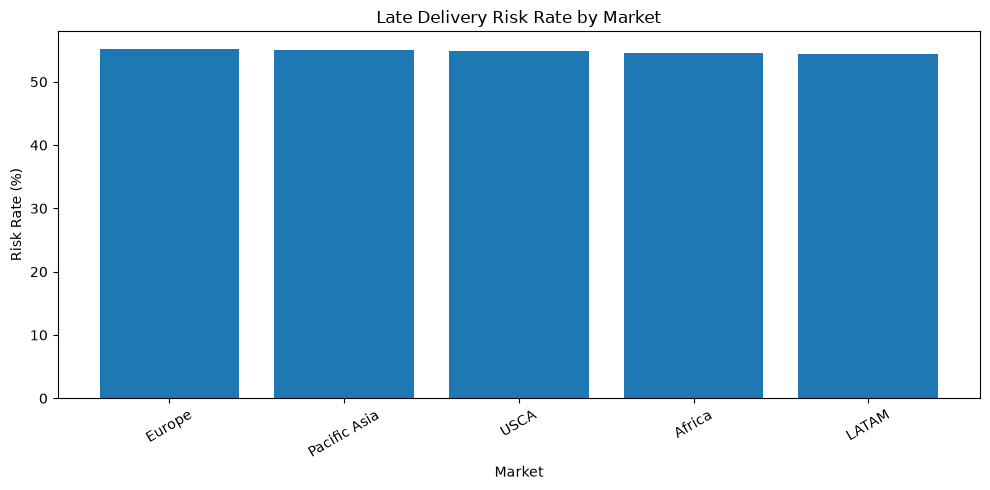

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    market_risk.index,
    market_risk["Risk_Rate_%"]
)

plt.title("Late Delivery Risk Rate by Market")
plt.xlabel("Market")
plt.ylabel("Risk Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Risk Rate by Region

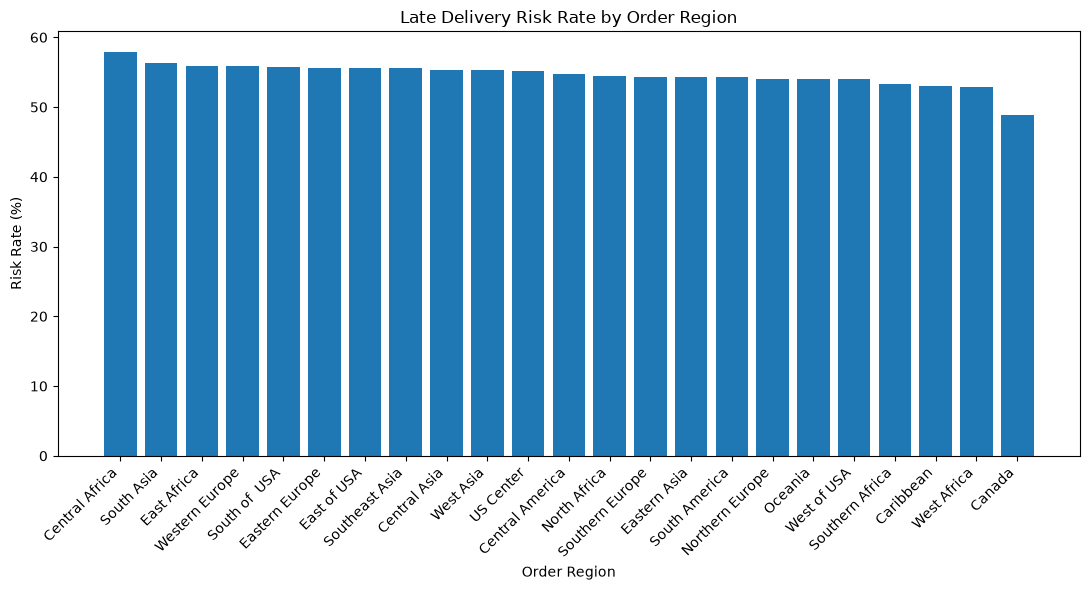

In [22]:
region_plot = region_risk.sort_values(
    "Risk_Rate_%",
    ascending=False
)

plt.figure(figsize=(11, 6))

plt.bar(
    region_plot.index,
    region_plot["Risk_Rate_%"]
)

plt.title("Late Delivery Risk Rate by Order Region")
plt.xlabel("Order Region")
plt.ylabel("Risk Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Top High Risk Areas

In [23]:
top_risk_regions = (
    region_risk
    .sort_values(
        ["Risk_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .head(10)
)

display(top_risk_regions)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Order Region,,,,,
Central Africa,1677,972,1018,57.96,60.70
South Asia,7731,4350,4523,56.27,58.50
East Africa,1852,1036,1064,55.94,57.45
Western Europe,27109,15140,15863,55.85,58.52
South of USA,4045,2256,2350,55.77,58.10
East of USA,6915,3849,4009,55.66,57.98
Eastern Europe,3920,2182,2252,55.66,57.45
Southeast Asia,9539,5297,5531,55.53,57.98
Central Asia,553,306,316,55.33,57.14


## Top High Risk Markets

In [24]:
top_risk_markets = (
    market_risk
    .sort_values(
        ["Risk_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .head(10)
)

display(top_risk_markets)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Market,,,,,
Europe,50252,27743,28989,55.21,57.69
Pacific Asia,41260,22712,23649,55.05,57.32
USCA,25799,14138,14744,54.80,57.15
Africa,11614,6340,6598,54.59,56.81
LATAM,51594,28044,29420,54.36,57.02


## Top High Risk by Shipping Modes

In [25]:
top_risk_modes = (
    shipping_mode_risk
    .sort_values(
        ["Risk_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .head(10)
)

display(top_risk_modes)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Risk_Rate_%,Actual_Delay_Rate_%
Shipping Mode,,,,,
First Class,27814,26513,27814,95.32,100.00
Second Class,35216,26987,28078,76.63,79.73
Same Day,9737,4454,4657,45.74,47.83
Standard Class,107752,41023,42851,38.07,39.77


## Risk Concentration analysis

In [26]:
risk_segment = (
    df_day5
    .groupby(["Shipping Mode", "Market"])
    .agg(
        Total_Shipments=("Late_delivery_risk", "size"),
        High_Risk_Shipments=("Late_delivery_risk", "sum"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum")
    )
)

risk_segment["Risk_Rate_%"] = (
    risk_segment["High_Risk_Shipments"]
    / risk_segment["Total_Shipments"]
    * 100
).round(2)

risk_segment["Actual_Delay_Rate_%"] = (
    risk_segment["Actual_Delayed_Shipments"]
    / risk_segment["Total_Shipments"]
    * 100
).round(2)

risk_segment = risk_segment.sort_values(
    ["Risk_Rate_%", "Total_Shipments"],
    ascending=[False, False]
)

display(risk_segment.head(20))

Total_Shipments  High_Risk_Shipments  \
Shipping Mode  Market                                               
First Class    Africa                   1727                 1675   
               Europe                   7892                 7562   
               USCA                     4008                 3814   
               Pacific Asia             6301                 5991   
               LATAM                    7886                 7471   
Second Class   Africa                   2164                 1675   
               Pacific Asia             8147                 6293   
               Europe                   9861                 7596   
               USCA                     5105                 3913   
               LATAM                    9939                 7510   
Same Day       LATAM                    2650                 1273   
               Europe                   2759                 1281   
               USCA                     1434                  637   
               Africa                    668                  294   
               Pacific Asia             2226                  969   
Standard Class Pacific Asia            24586                 9459   
               Africa                   7055                 2696   
               Europe                  29740                11304   
               LATAM                   31119                11790   
               USCA                    15252                 5774   

                             Actual_Delayed_Shipments  Risk_Rate_%  \
Shipping Mode  Market                                                
First Class    Africa                            1727        96.99   
               Europe                            7892        95.82   
               USCA                              4008        95.16   
               Pacific Asia                      6301        95.08   
               LATAM                             7886        94.74   
Second Class   Africa                            1732        77.40   
               Pacific Asia                      6552        77.24   
               Europe                            7887        77.03   
               USCA                              4061        76.65   
               LATAM                             7846        75.56   
Same Day       LATAM                             1354        48.04   
               Europe                            1341        46.43   
               USCA                               647        44.42   
               Africa                             317        44.01   
               Pacific Asia                       998        43.53   
Standard Class Pacific Asia                      9798        38.47   
               Africa                            2822        38.21   
               Europe                           11869        38.01   
               LATAM                            12334        37.89   
               USCA                              6028        37.86   

                             Actual_Delay_Rate_%  
Shipping Mode  Market                             
First Class    Africa                     100.00  
               Europe                     100.00  
               USCA                       100.00  
               Pacific Asia               100.00  
               LATAM                      100.00  
Second Class   Africa                      80.04  
               Pacific Asia                80.42  
               Europe                      79.98  
               USCA                        79.55  
               LATAM                       78.94  
Same Day       LATAM                       51.09  
               Europe                      48.60  
               USCA                        45.12  
               Africa                      47.46  
               Pacific Asia                44.83  
Standard Class Pacific Asia                39.85  
               Africa                      40.00  


## Day 5 Validation

In [27]:
day5_validation = {
    "Row Count Preserved": len(df_day5) == len(df_day4),

    "No Duplicate Rows":
        df_day5.duplicated().sum() == 0,

    "Late Delivery Risk Exists":
        "Late_delivery_risk" in df_day5.columns,

    "Risk Status Created":
        "Risk_Status" in df_day5.columns,

    "Valid Risk Values":
        set(
            df_day5["Late_delivery_risk"].dropna().unique()
        ).issubset({0, 1}),

    "Valid Risk Status":
        set(
            df_day5["Risk_Status"].dropna().unique()
        ).issubset({"High Risk", "Low Risk"}),

    "Risk Flag Consistent":
        (
            df_day5["Risk_Status"]
            ==
            np.where(
                df_day5["Late_delivery_risk"] == 1,
                "High Risk",
                "Low Risk"
            )
        ).all()
}

day5_validation_report = pd.DataFrame(
    list(day5_validation.items()),
    columns=["Validation", "Status"]
)

display(day5_validation_report)

,Validation,Status
0,Row Count Preserved,True
1,No Duplicate Rows,True
2,Late Delivery Risk Exists,True
3,Risk Status Created,True
4,Valid Risk Values,True
5,Valid Risk Status,True
6,Risk Flag Consistent,True


In [28]:
if day5_validation_report["Status"].all():
    print("DAY 5 DELAY RISK: PASS")
else:
    print("DAY 5 DELAY RISK: CHECK REQUIRED")

DAY 5 DELAY RISK: PASS


## Saving Day 5 Outputs

In [29]:
import os

os.makedirs("../data/analysis_data", exist_ok=True)

In [30]:
day5_path = "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"

df_day5.to_csv(
    day5_path,
    index=False,
    encoding="cp1252"
)

print("Day 5 dataset saved successfully.")
print(day5_path)

Day 5 dataset saved successfully.
../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv


### Risk KPI table

In [31]:
risk_kpi_path = "../data/analysis_data/APL_Day5_Risk_KPIs.csv"

risk_kpis.to_csv(
    risk_kpi_path,
    index=False,
    encoding="utf-8"
)

print(risk_kpi_path)

../data/analysis_data/APL_Day5_Risk_KPIs.csv


### Shipping-mode risk

In [32]:
shipping_risk_path = "../data/analysis_data/APL_Day5_Shipping_Mode_Risk.csv"

shipping_mode_risk.to_csv(
    shipping_risk_path,
    encoding="utf-8"
)

print(shipping_risk_path)

../data/analysis_data/APL_Day5_Shipping_Mode_Risk.csv


### Market risk

In [33]:
market_risk_path = "../data/analysis_data/APL_Day5_Market_Risk.csv"

market_risk.to_csv(
    market_risk_path,
    encoding="utf-8"
)

print(market_risk_path)

../data/analysis_data/APL_Day5_Market_Risk.csv


### Region risk

In [34]:
region_risk_path = "../data/analysis_data/APL_Day5_Region_Risk.csv"

region_risk.to_csv(
    region_risk_path,
    encoding="utf-8"
)

print(region_risk_path)

../data/analysis_data/APL_Day5_Region_Risk.csv


### Severity analysis

In [35]:
severity_risk_path = "../data/analysis_data/APL_Day5_Risk_Severity.csv"

severity_risk.to_csv(
    severity_risk_path,
    encoding="utf-8"
)

print(severity_risk_path)

../data/analysis_data/APL_Day5_Risk_Severity.csv


### Validation report

In [36]:
validation_path = "../data/analysis_data/APL_Day5_Risk_Validation.csv"

day5_validation_report.to_csv(
    validation_path,
    index=False,
    encoding="utf-8"
)

print(validation_path)

../data/analysis_data/APL_Day5_Risk_Validation.csv


## Final Day 5 business insights

In [37]:
highest_risk_mode = shipping_mode_risk["Risk_Rate_%"].idxmax()
highest_risk_market = market_risk["Risk_Rate_%"].idxmax()
highest_risk_region = region_risk["Risk_Rate_%"].idxmax()

print("Highest-risk shipping mode:", highest_risk_mode)
print("Highest-risk market:", highest_risk_market)
print("Highest-risk region:", highest_risk_region)

print(
    "Overall late-delivery risk rate:",
    round(
        df_day5["Late_delivery_risk"].mean() * 100,
        2
    ),
    "%"
)

Highest-risk shipping mode: First Class
Highest-risk market: Europe
Highest-risk region: Central Africa
Overall late-delivery risk rate: 54.83 %


In [38]:
print(
    "Overall actual delay rate:",
    round(
        df_day5["Is_Delayed"].mean() * 100,
        2
    ),
    "%"
)

Overall actual delay rate: 57.28 %
